# Figure S30: Trait prioritization for four genes

Draw four saved signed-effect percentile summaries for F10, ANGPTL3, SERPINF2, and IFT80.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_PAPER_ROOT` to the local
paper directory and `QTL_SOURCE_ROOT` to the figure checkout with staged inputs
and saved objects. For example, set these variables in the R session before
you run the cells. Paths can contain spaces.

Run the cells from top to bottom. The notebook reads the recorded figure data.
It does not rerun upstream QTL mapping unless a section explicitly says so.
New PDFs and PNGs go to `notebook_outputs/`. Inputs stay in place.
The source scripts are in `notebooks/current/`. Figures shown below are aggregate
plots. Do not print participant tables into a saved notebook.


## Scope

Upper-tail percentage is 100 minus percentile. Lower-tail percentage equals percentile. These ranks are not P values or individual disease-risk estimates.

VUS and unclassified labels retain the source classification. No association, clinical-classification, or ranking analysis is repeated.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the November 2 figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  path <- file.path(root, relative)
  if (!file.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  input_records[[paste(variable, relative, sep = ":")]] <- list(
    root = variable, path = relative, md5 = unname(tools::md5sum(path)))
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display the archived November 2 submission image for Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read the saved trait ranks

Rebuild S30 from four saved signed-effect percentile ranks. No association analysis, clinical classification, or ranking is repeated. The input contains four gene–trait summaries and no participant records.


In [2]:
panels <- readr::read_tsv(paper_file("Supplemental Figures/01_Supplemental_drafts/Figure5_trait_prioritization/trait_prioritization_data.tsv"), show_col_types = FALSE) %>%
  mutate(gene = factor(gene, c("F10", "ANGPTL3", "SERPINF2", "IFT80")))
stopifnot(nrow(panels) == 4L, !anyNA(panels), all(dplyr::between(panels$percentile, 0, 100)),
          all(abs(panels$x - if_else(panels$tail == "Lower tail", panels$percentile / 5, (panels$percentile - 95) / 5)) < 1e-12))
ticks <- tidyr::crossing(gene = panels$gene, x = seq(0, 1, 0.2)) %>%
  mutate(label = if_else(gene == "ANGPTL3", x * 5, 95 + x * 5))


## Draw the four selected examples

F10, SERPINF2, and IFT80 show the 95th–100th percentile range. ANGPTL3 shows the 0th–5th range. The upper-tail percentage is 100 minus the percentile; the lower-tail percentage is the percentile. These directional ranks are not association P values or individual disease-risk estimates.


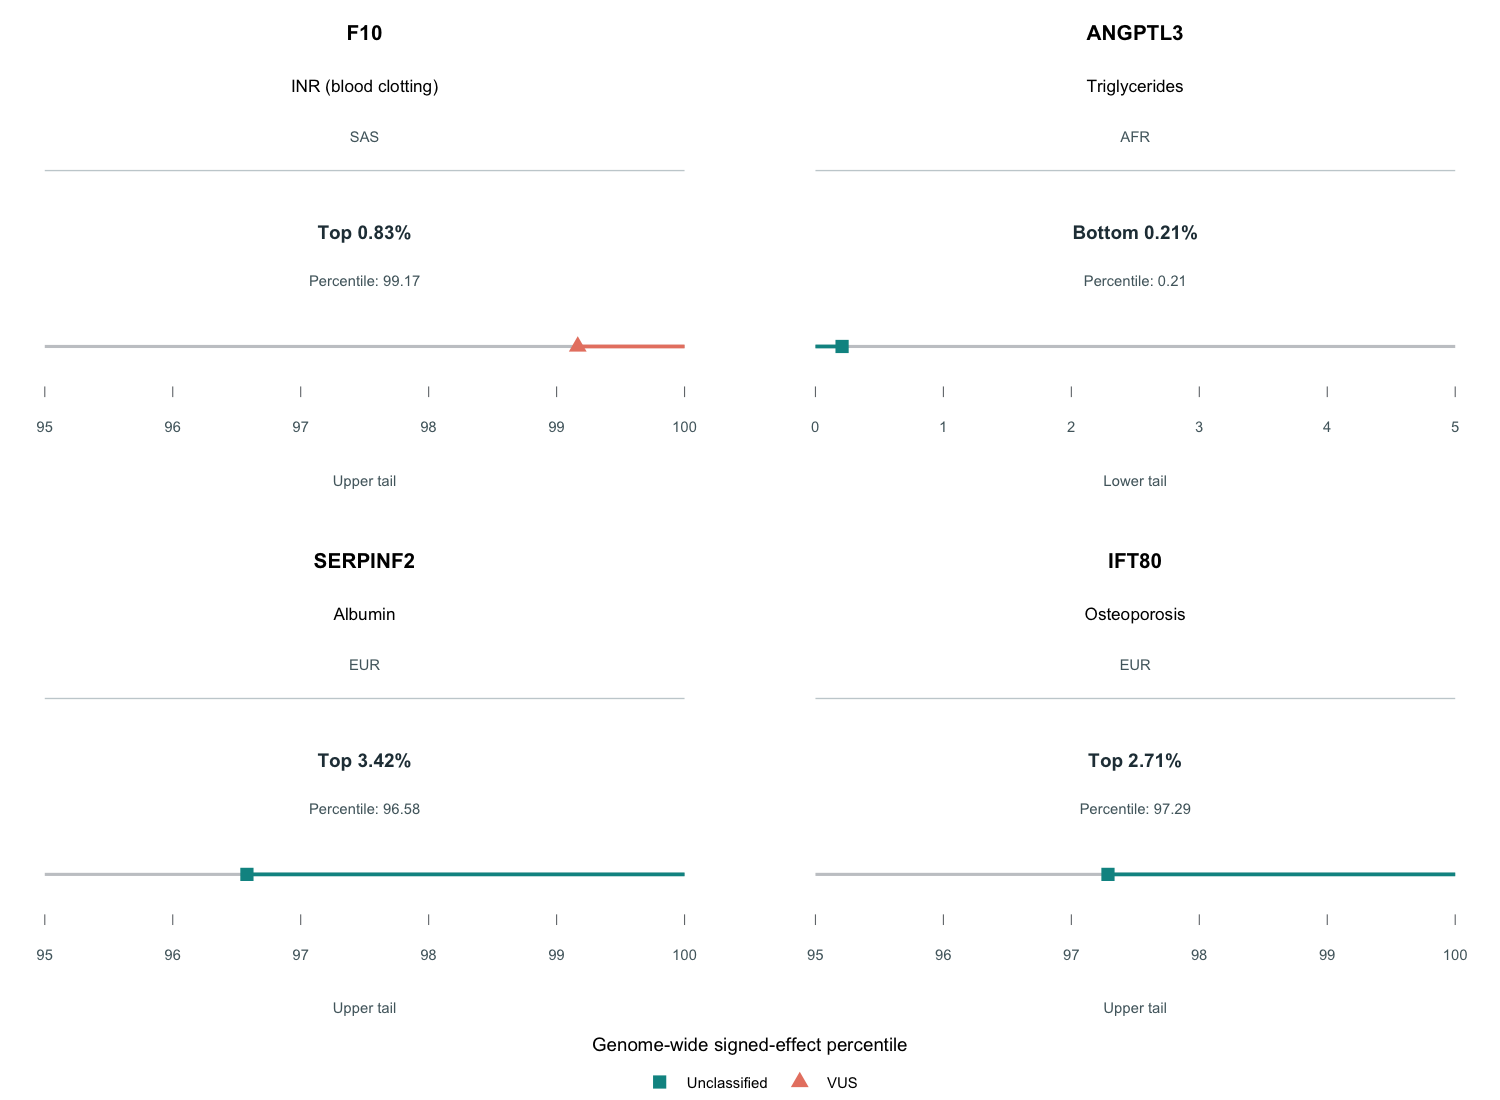

In [3]:
figure <- ggplot() +
  geom_text(data = panels, aes(0.5, 1.24, label = gene), size = 3.5, fontface = "bold") +
  geom_text(data = panels, aes(0.5, 1.04, label = trait), size = 2.9) +
  geom_text(data = panels, aes(0.5, 0.85, label = ancestry), size = 2.5, colour = "#52676D") +
  annotate("segment", x = 0, xend = 1, y = 0.72, yend = 0.72, colour = "#C7D0D3", linewidth = 0.3) +
  geom_text(data = panels, aes(0.5, 0.49, label = label), size = 3.2, fontface = "bold", colour = "#263B45") +
  geom_text(data = panels, aes(0.5, 0.31, label = rank_label), size = 2.5, colour = "#52676D") +
  annotate("segment", x = 0, xend = 1, y = 0.06, yend = 0.06, colour = "#C6C9CC", linewidth = 0.7) +
  geom_segment(data = panels, aes(x = x, xend = tail_end, colour = class), y = 0.06, yend = 0.06, linewidth = 0.85, show.legend = FALSE) +
  geom_point(data = panels, aes(x, 0.06, colour = class, shape = class), size = 2.7) +
  geom_segment(data = ticks, aes(x = x, xend = x), y = -0.09, yend = -0.13, colour = "#73777B", linewidth = 0.25) +
  geom_text(data = ticks, aes(x, -0.24, label = label), size = 2.5, colour = "#52676D") +
  geom_text(data = panels, aes(0.5, -0.44, label = tail), size = 2.5, colour = "#52676D") +
  facet_wrap(vars(gene), ncol = 2) +
  scale_colour_manual(values = c(VUS = "#E88471", Unclassified = "#009392"), name = NULL) +
  scale_shape_manual(values = c(VUS = 17, Unclassified = 15), name = NULL) +
  labs(x = "Genome-wide signed-effect percentile") +
  coord_cartesian(xlim = c(-0.07, 1.07), ylim = c(-0.51, 1.36), expand = FALSE, clip = "off") +
  theme_void(base_size = 9) +
  theme(strip.text = element_blank(), panel.spacing.x = grid::unit(7, "mm"), panel.spacing.y = grid::unit(5, "mm"),
        axis.title.x = element_text(size = 9, margin = margin(t = 4)), legend.position = "bottom")
print(figure)


## Save aggregate outputs

Save the figure and the four source summaries. VUS and unclassified labels retain the source classification and are not a new clinical assessment.


In [4]:
save_plot(figure, "supplements/S30", 184, 125)
readr::write_tsv(panels, output_file("supplements/S30_trait_ranks.tsv"))


Export aggregate plot: supplements/S30
